# Image colourisation with Azulero

<img style="position: absolute; right: 60px; top: 40px; height: 160px; width: 160px" src="https://datalabs.esa.int/datalab-icon/c11e47af-7ce9-4281-b3b5-475a180a256f" /> 


<div style="width: 70%;">

Copyright (c) Antoine Basset, 2026.

This file is subject to the terms and conditions defined in file `LICENSE.txt`, which is part of this source code package. No part of the package, including this file, may be copied, modified, propagated, or distributed except according to the terms contained in the file `LICENSE.txt`.

</div>

**Last modified:** 2026-11-11

**Notebook summary:**

This notebook shows how to create colour Euclid images with Azulero, making use of the direct access to the data offered by Datalabs. Azulero cleans and enhances MER data and combines the four Euclid photometric channels (VIS, Y, J, H) into an RGB image. It was developed by Antoine Basset (CNES) primarily as a command-line tool, however, its core functionality is also available via a Python API. This notebook demonstrates the use of the API only. Consult [Azulero documentation](https://kabasset.github.io/azulero/v2.1.0/index.html) to find out about Azulero's full processing capabilities, including producing collages of cutouts and movies.

Overview of the contents:
* Define a target (name or coordinates, cutout size and dataset release);
* Find the tiles which contain the target;
* Find the tile datafiles;
* Extract the cutouts;
* Render the colour image;
* Display the colour image.

This notebook corresponds to the following command line, which also works in Datalabs terminals:

```
azul retrieve NVSSJ180436+672324 -r 30s --dsr DR1_R1 --survey WIDE -n 1 --data labs | azul process
```

**Useful links:**
* [Azulero API reference](https://kabasset.github.io/azulero/v2.1.0/python.html)
* [Azulero on GitHub](https://github.com/kabasset/azulero)

**Running the notebook:** 

- This notebook has **read-only permissions**. You can still run and edit cells but if you would like to save your changes then you have to save the notebook to a different location - your workspace for example.
- The notebook is intended to be run using the COLOUR-TOOLS kernel that has all the necessary packages included.

***


**Before running this notebook:** Please make sure you update to the latest version of Azulero installed. Run the cell below and **restart the kernel** afterwards.

In [18]:
%pip install --upgrade azulero

Note: you may need to restart the kernel to use updated packages.


### Import dependencies, including azulero.api

In [19]:
from astropy.coordinates import Angle, SkyCoord  # Required for cutouts only
from astropy.io import fits  # Required for reading data or WCS
from astropy.wcs import WCS  # Required for reading WCS only
import matplotlib.pyplot as plt  # Required for displaying images only
from pathlib import Path  # Required for retrieval only

from azulero import api as azul

## 1. Retrieve

### 1.1 Define target

First, we define a target and cutout radius.

In [20]:
coord = SkyCoord.from_name("NVSSJ180436+672324")
radius = Angle("30s")

### 1.2 Setup data provider

Then, we instantiate some [data provider based on its name](https://kabasset.github.io/azulero/develop/retrieve.html#data-provider-setup)
and we specify that the datafiles are stored in the Datalabs with option `data_store="labs"`.

In [21]:
provider = azul.DataProvider("PDR", data_store="labs")

### 1.3 Find tile indices

We can now find the indices of the tiles which contain our target.

The third parameter (survey mode) accepts one or several of the following values: `"DEEP"`, `"WIDE"` or `"UNKNOWN"`.
The latter is dedicated to the Q1 dataset release `"Q1_R1"`, where the survey mode was not ingested.
Let's use `"WIDE"` here in order to later demonstrate the input stacking when the object has been observed several times.

In [ ]:
tiles = provider.query_coord_tiles(coord, ["DR1_R1"], ["WIDE"])
for t in tiles:
    print(t)

### 1.4 Find datafile names

Each file may contain one or several datafiles per photometric band.
They are all discovered with `query_tile_datafiles()`.

In [5]:
datafiles = provider.query_tile_datafiles(tiles[0])
for d in datafiles:
    print(d)

EUC_MER_BGSUB-MOSAIC-NIR-H_TILE102160060-29308F_20250630T211124.029780Z_00.00.fits
EUC_MER_BGSUB-MOSAIC-NIR-H_TILE102160060-63CA86_20250723T042158.317077Z_00.00.fits
EUC_MER_BGSUB-MOSAIC-NIR-H_TILE102160060-7D396B_20250721T034438.159016Z_00.00.fits
EUC_MER_BGSUB-MOSAIC-NIR-H_TILE102160060-8F1C26_20250703T110138.056866Z_00.00.fits
EUC_MER_BGSUB-MOSAIC-NIR-H_TILE102160060-C00B6C_20250724T011614.398604Z_00.00.fits
EUC_MER_BGSUB-MOSAIC-NIR-H_TILE102160060-C6A0A3_20250716T090242.286684Z_00.00.fits
EUC_MER_BGSUB-MOSAIC-NIR-H_TILE102160060-D1B5DA_20250723T023537.754309Z_00.00.fits
EUC_MER_BGSUB-MOSAIC-NIR-H_TILE102160060-E8D826_20250708T193839.125959Z_00.00.fits
EUC_MER_BGSUB-MOSAIC-NIR-H_TILE102160060-EAE136_20250716T065032.639348Z_00.00.fits
EUC_MER_BGSUB-MOSAIC-NIR-H_TILE102160060-FF8C0D_20250721T075718.314630Z_00.00.fits
EUC_MER_BGSUB-MOSAIC-NIR-J_TILE102160060-3A5CDC_20250716T091345.348907Z_00.00.fits
EUC_MER_BGSUB-MOSAIC-NIR-J_TILE102160060-762371_20250716T065113.091358Z_00.00.fits
EUC_

### 1.5 Download cutouts

Now that we have the datafile names, we can build and download each of the cutouts with `download_cutouts()`.
The workdir must be unique for each tile and target.
In this example, we have a single target and tile and therefore simply create a new workdir.

In [6]:
workdir = Path("/media/user/example_notebook_outputs/azulero_colourisation/")
workdir.mkdir(parents=True, exist_ok=True)
cutouts = provider.download_cutouts(datafiles, workdir, coord, radius)
for c in cutouts:
    print(str(c))

/media/user/example_notebook_outputs/azulero_colourisation/EUC_MER_BGSUB-MOSAIC-NIR-H_TILE102160060-29308F_20250630T211124.029780Z_00.00.fits
/media/user/example_notebook_outputs/azulero_colourisation/EUC_MER_BGSUB-MOSAIC-NIR-H_TILE102160060-63CA86_20250723T042158.317077Z_00.00.fits
/media/user/example_notebook_outputs/azulero_colourisation/EUC_MER_BGSUB-MOSAIC-NIR-H_TILE102160060-7D396B_20250721T034438.159016Z_00.00.fits
/media/user/example_notebook_outputs/azulero_colourisation/EUC_MER_BGSUB-MOSAIC-NIR-H_TILE102160060-8F1C26_20250703T110138.056866Z_00.00.fits
/media/user/example_notebook_outputs/azulero_colourisation/EUC_MER_BGSUB-MOSAIC-NIR-H_TILE102160060-C00B6C_20250724T011614.398604Z_00.00.fits
/media/user/example_notebook_outputs/azulero_colourisation/EUC_MER_BGSUB-MOSAIC-NIR-H_TILE102160060-C6A0A3_20250716T090242.286684Z_00.00.fits
/media/user/example_notebook_outputs/azulero_colourisation/EUC_MER_BGSUB-MOSAIC-NIR-H_TILE102160060-D1B5DA_20250723T023537.754309Z_00.00.fits
/media

## 2. Process

In this notebook, we use files as input and therefore rely on `read_iyjh()`.
In general, the Python API makes more sense when you already have the data in memory and bypass IOs.
Variable `iyjh` below is a NumPy stack of 2D arrays for channels I, Y, J, H.

Function `process_iyjh()` accepts an optional parameter to customize the transformation:
see the [API documentation](https://kabasset.github.io/azulero/develop/python.html#azulero.api.Transform).

In [7]:
iyjh = azul.read_iyjh(workdir)
bgr = azul.process_iyjh(iyjh)

WARNING - 10 files found with pattern: *VIS*.fits
WARNING - 10 files found with pattern: *NIR-Y*.fits
WARNING - 9 files found with pattern: *NIR-J*.fits
WARNING - 10 files found with pattern: *NIR-H*.fits


We get a colour image (beware the Blue, Green, Red channel ordering) which we can plot either with pixel or sky coordinates, as follows:

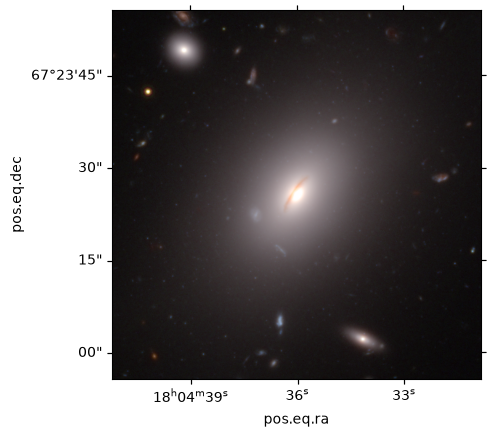

In [8]:
# Pixel coordinates
# plt.imshow(bgr[..., ::-1], origin='lower')

# Sky coordinates
with fits.open(cutouts[0]) as f:
    wcs = WCS(f[0].header)
fig, ax = plt.subplots(subplot_kw=dict(projection=wcs))
ax.imshow(bgr[..., ::-1], origin='lower')